# Assignment 3
# Loan Eligibility Prediction
Model training, hyperparameter tuning, optimization, evaluation and the complete machine-learning pipeline.

**Group 14:** Khadija Fatima · Memoona Ghufran · Ramisha Rahat

# **1. Setup and Loading the Data**

In [ ]:
#Loan Eligibility Prediction: Model Training, Optimization, Evaluation and Final Pipeline
#Import Libraries

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_validate,
                                     cross_val_predict, learning_curve)
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, VotingClassifier, StackingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, make_scorer, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

In [ ]:
#Loading the dataset (works on Colab and locally)
DATA_PATH = "Loan Eligibility Prediction.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/content/" + DATA_PATH):
    DATA_PATH = "/content/" + DATA_PATH

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (614, 13)


,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [ ]:
# Cleaning from Assignment 2: no missing values, drop duplicates and the identifier column
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().drop(columns=["Customer_ID"]).reset_index(drop=True)
print("Shape after cleaning:", df.shape)
print(df["Loan_Status"].value_counts(normalize=True).round(3))

Missing values: 0
Duplicate rows: 0
Shape after cleaning: (614, 12)
Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


# **2. Reusable Preprocessing Module**

In Assignment 2 the outlier capping, feature engineering, encoding and scaling were done step by step on the whole dataset. For modelling, the **same steps** are wrapped in a scikit-learn `Pipeline` so that:

- every statistic (IQR outlier bounds, medians, scaler mean and standard deviation) is learned from the **training data only**, which prevents data leakage, even inside cross-validation;
- the final saved model accepts the **raw applicant columns** and does all the preprocessing itself.

In [ ]:
# Preprocessing pipeline: the Assignment 2 steps (outlier capping, feature engineering,
# encoding, scaling) inside a scikit-learn Pipeline, so every statistic is learned
# from training data only.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAW_FEATURES = ["Gender", "Married", "Dependents", "Education", "Self_Employed",
                "Applicant_Income", "Coapplicant_Income", "Loan_Amount",
                "Loan_Amount_Term", "Credit_History", "Property_Area"]

# Final 15 model features (same as the Assignment 2 output)
FEATURES = ["Gender", "Married", "Dependents", "Education", "Self_Employed",
            "Loan_Amount", "Loan_Amount_Term", "Credit_History", "EMI",
            "Balance_Income", "Loan_to_Income", "Has_Coapplicant",
            "Total_Income_log", "Property_Area_Semiurban", "Property_Area_Urban"]

SCALE_COLS = ["Dependents", "Loan_Amount", "Loan_Amount_Term", "EMI",
              "Balance_Income", "Loan_to_Income", "Total_Income_log"]

CAP_COLS = ("Applicant_Income", "Coapplicant_Income", "Loan_Amount")

BINARY_MAPS = {"Gender": {"Male": 1, "Female": 0},
               "Married": {"Yes": 1, "No": 0},
               "Education": {"Graduate": 1, "Not Graduate": 0},
               "Self_Employed": {"Yes": 1, "No": 0}}


class LoanFeatureEngineer(BaseEstimator, TransformerMixin):
    """Raw applicant columns -> the 15 engineered/encoded features of Assignment 2.

    fit()       learns the IQR outlier bounds from the TRAINING data only.
    transform() caps outliers, encodes categoricals and builds the engineered features.
    """

    def __init__(self, cap_cols=CAP_COLS):
        self.cap_cols = cap_cols

    def fit(self, X, y=None):
        self.caps_ = {}
        for col in self.cap_cols:
            q1, q3 = X[col].quantile(0.25), X[col].quantile(0.75)
            iqr = q3 - q1
            self.caps_[col] = (max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr)
        return self

    def transform(self, X):
        d = X.copy()
        for col, mapping in BINARY_MAPS.items():
            d[col] = d[col].map(mapping)
        d["Dependents"] = pd.to_numeric(
            d["Dependents"].astype(str).str.replace("+", "", regex=False), errors="coerce")
        for col, (low, up) in self.caps_.items():
            d[col] = d[col].clip(lower=low, upper=up)

        d["Total_Income"] = d["Applicant_Income"] + d["Coapplicant_Income"]
        d["EMI"] = d["Loan_Amount"] / d["Loan_Amount_Term"]
        d["Balance_Income"] = d["Total_Income"] - d["EMI"] * 1000
        d["Loan_to_Income"] = d["Loan_Amount"] / d["Total_Income"]
        d["Has_Coapplicant"] = (d["Coapplicant_Income"] > 0).astype(int)
        d["Total_Income_log"] = np.log1p(d["Total_Income"])
        d["Property_Area_Semiurban"] = (d["Property_Area"] == "Semiurban").astype(int)
        d["Property_Area_Urban"] = (d["Property_Area"] == "Urban").astype(int)
        return d[FEATURES].replace([np.inf, -np.inf], np.nan)


def build_preprocessor(features=FEATURES):
    """Impute + scale the numeric columns, impute the binary columns."""
    scale = [c for c in SCALE_COLS if c in features]
    other = [c for c in features if c not in SCALE_COLS]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), scale),
        ("bin", SimpleImputer(strategy="most_frequent"), other),
    ])


def make_pipeline_for(estimator, features=FEATURES):
    """Complete pipeline: raw data -> feature engineering -> preprocessing -> model."""
    return Pipeline([("fe", LoanFeatureEngineer()),
                     ("prep", build_preprocessor(features)),
                     ("model", estimator)])


def predict_loan(bundle, raw_df):
    """Predict approval for raw applicant rows using a saved bundle (see notebook)."""
    proba = bundle["model"].predict_proba(raw_df[RAW_FEATURES])[:, 1]
    label = np.where(proba >= bundle["threshold"], "Y", "N")
    return pd.DataFrame({"Approval_Probability": proba.round(3),
                         "Loan_Status_Pred": label}, index=raw_df.index)

In [ ]:
print("Raw columns used as input   :", len(RAW_FEATURES))
print("Final model features        :", len(FEATURES))
print(FEATURES)

Raw columns used as input   : 11
Final model features        : 15
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'EMI', 'Balance_Income', 'Loan_to_Income', 'Has_Coapplicant', 'Total_Income_log', 'Property_Area_Semiurban', 'Property_Area_Urban']


In [ ]:
# Quick check: the pipeline's feature engineering step turns raw columns into the 15 features
LoanFeatureEngineer().fit(df).transform(df.drop(columns=["Loan_Status"])).head()

,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount,Loan_Amount_Term,Credit_History,EMI,Balance_Income,Loan_to_Income,Has_Coapplicant,Total_Income_log,Property_Area_Semiurban,Property_Area_Urban
0,0,0,0,1,0,9.0,360,1,0.025000,2353.000000,0.003785,0,7.774436,0,1
1,1,1,2,1,0,17.0,120,1,0.141667,2243.333333,0.007128,1,7.777374,0,1
2,1,0,0,0,0,25.0,120,1,0.208333,3411.666667,0.006906,0,8.194506,1,0
3,1,1,0,1,1,25.0,120,1,0.208333,3250.666667,0.007228,0,8.149024,1,0
4,1,1,1,1,0,26.0,360,1,0.072222,6427.777778,0.004000,1,8.779711,1,0


# **3. Train / Validation / Test Split**

The data is split three ways with stratification (so all parts keep the same ~69% approval ratio):

| Part | Share | Purpose |
|---|---|---|
| **Training** | 60% | Fit the baseline models |
| **Validation** | 20% | Compare baseline models and choose what to tune |
| **Test** | 20% | Touched only once at the end for the final, unbiased result |

The test set uses the same `test_size=0.2` and `random_state=42` as Assignment 2, so it holds exactly the same applicants. For hyperparameter tuning, training + validation (80%) are combined and **5-fold stratified cross-validation** is used, because 614 rows is too small to rely on one validation split.

In [ ]:
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# 80% train+validation / 20% test (same as Assignment 2)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# 60% train / 20% validation (25% of the remaining 80%)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=y_trainval)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test), len(X)],
    "Share %": [round(100 * n / len(X), 1) for n in (len(X_train), len(X_val), len(X_test), len(X))],
    "Approved %": [round(100 * s.mean(), 1) for s in (y_train, y_val, y_test, y)]
}, index=["Training", "Validation", "Test", "Total"])
split_summary

,Rows,Share %,Approved %
Training,368,59.9,68.8
Validation,123,20.0,68.3
Test,123,20.0,69.1
Total,614,100.0,68.7


# **4. Models Used and Evaluation Metrics**


In [ ]:
# Helper: evaluate any fitted pipeline on any data (threshold 0.5 unless stated)
def evaluate(model, X_, y_, threshold=0.5):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred, zero_division=0),
            "F1": f1_score(y_, pred, zero_division=0),
            "Macro_F1": f1_score(y_, pred, average="macro", zero_division=0),
            "ROC_AUC": roc_auc_score(y_, proba)}

# Helper: cross-validated scores of an unfitted pipeline
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"Accuracy": "accuracy", "F1": "f1", "Macro_F1": "f1_macro", "ROC_AUC": "roc_auc",
           "Specificity": make_scorer(recall_score, pos_label=0)}

def cv_scores(model, X_, y_, cv=rcv):
    res = cross_validate(clone(model), X_, y_, cv=cv, scoring=scoring, n_jobs=-1)
    return {k: res[f"test_{k}"].mean() for k in scoring}

# **5. Baseline Models (Default Settings)**

All models are first trained with their **default** settings on the training set (60%) and compared on the **validation set** (20%). The training accuracy is also shown, to spot overfitting.

In [ ]:
baseline_models = {
    "Dummy (majority)":    DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN":                 KNeighborsClassifier(),
    "SVM (RBF)":           SVC(probability=True, random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost":            AdaBoostClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, est in baseline_models.items():
    pipe = make_pipeline_for(est)
    pipe.fit(X_train, y_train)
    tr, va = evaluate(pipe, X_train, y_train), evaluate(pipe, X_val, y_val)
    rows.append({"Model": name, "Train_Acc": tr["Accuracy"],
                 **{f"Val_{k}": v for k, v in va.items()}})

baseline_df = (pd.DataFrame(rows).set_index("Model")
               .round(3).sort_values("Val_ROC_AUC", ascending=False))
baseline_df

,Train_Acc,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_Macro_F1,Val_ROC_AUC
Model,,,,,,,
SVM (RBF),0.826,0.846,0.822,0.988,0.897,0.793,0.826
Gradient Boosting,0.927,0.829,0.818,0.964,0.885,0.776,0.801
Random Forest,1.000,0.821,0.810,0.964,0.880,0.763,0.790
AdaBoost,0.810,0.862,0.838,0.988,0.907,0.819,0.785
Logistic Regression,0.802,0.829,0.806,0.988,0.888,0.766,0.779
Naive Bayes,0.802,0.846,0.828,0.976,0.896,0.797,0.761
KNN,0.769,0.707,0.722,0.929,0.812,0.573,0.693
Decision Tree,1.000,0.683,0.800,0.714,0.755,0.653,0.665
Dummy (majority),0.688,0.683,0.683,1.000,0.812,0.406,0.500


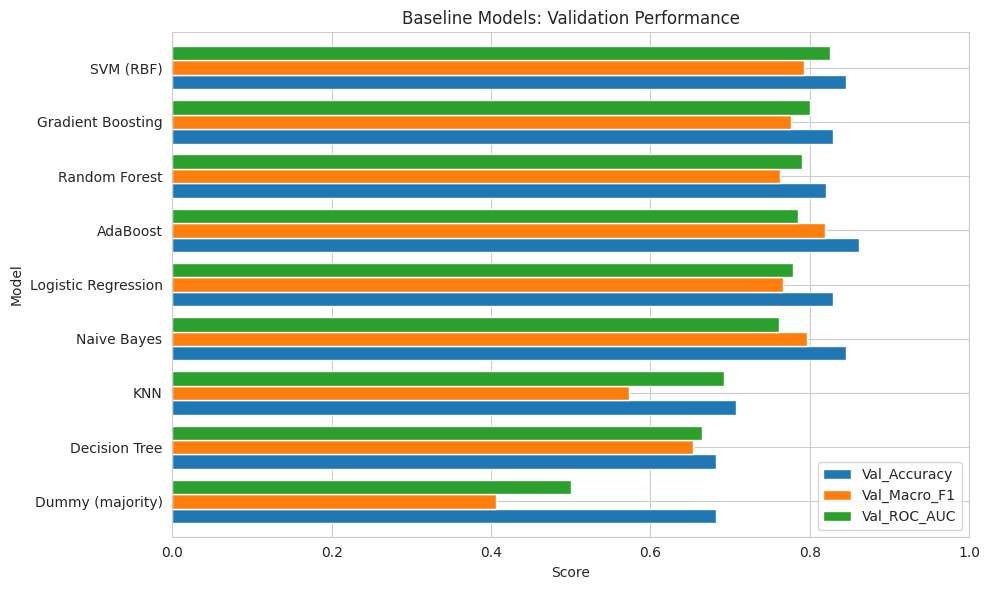

In [ ]:
# Visual comparison on the validation set
ax = (baseline_df[["Val_Accuracy", "Val_Macro_F1", "Val_ROC_AUC"]]
      .sort_values("Val_ROC_AUC").plot.barh(figsize=(10, 6), width=0.8))
ax.set_title("Baseline Models: Validation Performance")
ax.set_xlabel("Score")
ax.set_xlim(0, 1)
plt.tight_layout()
save_fig("01_baseline_validation")
plt.show()

# **6. Handling Class Imbalance**

About 31% of the loans are rejected. A model can reach a good accuracy by mostly approving, while failing to catch the risky applicants. `class_weight="balanced"` gives the minority class (rejected) a higher weight during training. Each setting is compared with 5-fold CV repeated 3 times on the training + validation data. **Specificity** shows how many truly rejected loans are caught.

In [ ]:
imbalance_models = {
    "Logistic Regression": lambda cw: LogisticRegression(max_iter=1000, class_weight=cw),
    "SVM (RBF)":           lambda cw: SVC(probability=True, class_weight=cw, random_state=RANDOM_STATE),
    "Decision Tree":       lambda cw: DecisionTreeClassifier(max_depth=4, class_weight=cw, random_state=RANDOM_STATE),
    "Random Forest":       lambda cw: RandomForestClassifier(max_depth=5, class_weight=cw, random_state=RANDOM_STATE),
}

rows = []
for name, make in imbalance_models.items():
    for cw in [None, "balanced"]:
        s = cv_scores(make_pipeline_for(make(cw)), X_trainval, y_trainval)
        rows.append({"Model": name, "class_weight": str(cw), **s})

imbalance_df = pd.DataFrame(rows).round(3)
imbalance_df[["Model", "class_weight", "Accuracy", "Macro_F1", "Specificity", "ROC_AUC"]]

,Model,class_weight,Accuracy,Macro_F1,Specificity,ROC_AUC
0,Logistic Regression,None,0.802,0.721,0.424,0.719
1,Logistic Regression,balanced,0.745,0.692,0.526,0.718
2,SVM (RBF),None,0.804,0.715,0.400,0.749
3,SVM (RBF),balanced,0.772,0.715,0.521,0.739
4,Decision Tree,None,0.809,0.738,0.469,0.720
5,Decision Tree,balanced,0.759,0.702,0.515,0.733
6,Random Forest,None,0.814,0.741,0.456,0.753
7,Random Forest,balanced,0.803,0.738,0.491,0.741


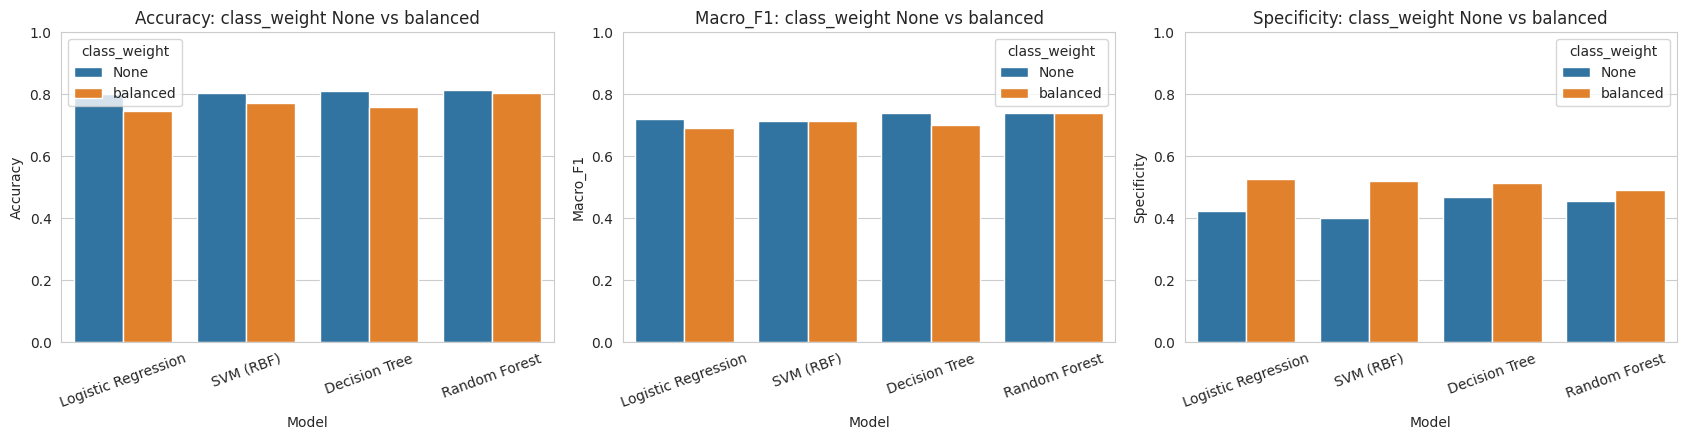

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["Accuracy", "Macro_F1", "Specificity"]):
    sns.barplot(data=imbalance_df, x="Model", y=metric, hue="class_weight", ax=ax)
    ax.set_title(f"{metric}: class_weight None vs balanced")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
save_fig("02_class_weight")
plt.show()

# **7. Hyperparameter Tuning**

The six most promising model families are tuned using **5-fold stratified cross-validation** on training + validation (490 applicants), with **ROC-AUC** as the scoring metric:

- **GridSearchCV** (tries every combination) for Logistic Regression, KNN, SVM and Decision Tree, which have small search spaces;
- **RandomizedSearchCV** (samples 40 random combinations) for Random Forest and Gradient Boosting, which have larger search spaces.

`class_weight` is included in the search space where the model supports it. The test set is **not** used here.

In [ ]:
tuning_setups = {
    "Logistic Regression": ("grid", LogisticRegression(max_iter=2000), {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]}),

    "KNN": ("grid", KNeighborsClassifier(), {
        "model__n_neighbors": list(range(3, 32, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]}),

    "SVM (RBF)": ("grid", SVC(probability=True, random_state=RANDOM_STATE), {
        "model__kernel": ["rbf", "linear"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.001, 0.01, 0.1],
        "model__class_weight": [None, "balanced"]}),

    "Decision Tree": ("grid", DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [2, 3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__class_weight": [None, "balanced"]}),

    "Random Forest": ("random", RandomForestClassifier(random_state=RANDOM_STATE), {
        "model__n_estimators": randint(100, 500),
        "model__max_depth": [3, 4, 5, 6, 8, None],
        "model__min_samples_leaf": randint(1, 15),
        "model__min_samples_split": randint(2, 20),
        "model__max_features": ["sqrt", 0.3, 0.5, 0.7],
        "model__class_weight": [None, "balanced", "balanced_subsample"]}),

    "Gradient Boosting": ("random", GradientBoostingClassifier(random_state=RANDOM_STATE), {
        "model__n_estimators": randint(50, 300),
        "model__learning_rate": uniform(0.01, 0.19),
        "model__max_depth": randint(1, 5),
        "model__subsample": uniform(0.6, 0.4),
        "model__min_samples_leaf": randint(1, 15)}),
}

tuned, rows = {}, []
for name, (kind, est, space) in tuning_setups.items():
    pipe = make_pipeline_for(est)
    if kind == "grid":
        search = GridSearchCV(pipe, space, scoring="roc_auc", cv=cv5, n_jobs=-1)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=40, scoring="roc_auc", cv=cv5,
                                    n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(X_trainval, y_trainval)
    tuned[name] = search.best_estimator_
    best = {}
    for k, v in search.best_params_.items():
        v = v.item() if hasattr(v, "item") else v
        best[k.replace("model__", "")] = round(v, 3) if isinstance(v, float) else v
    rows.append({"Model": name, "Search": "GridSearchCV" if kind == "grid" else "RandomizedSearchCV",
                 "Best_CV_ROC_AUC": round(search.best_score_, 4), "Best_Parameters": best})
    print(f"{name:20s} best CV ROC-AUC = {search.best_score_:.4f}")

tuning_df = pd.DataFrame(rows).set_index("Model")
pd.set_option("display.max_colwidth", 200)
tuning_df

Logistic Regression  best CV ROC-AUC = 0.7138
KNN                  best CV ROC-AUC = 0.6685
SVM (RBF)            best CV ROC-AUC = 0.7486
Decision Tree        best CV ROC-AUC = 0.7675
Random Forest        best CV ROC-AUC = 0.7613
Gradient Boosting    best CV ROC-AUC = 0.7660


,Search,Best_CV_ROC_AUC,Best_Parameters
Model,,,
Logistic Regression,GridSearchCV,0.7138,"{'C': 100, 'class_weight': None}"
KNN,GridSearchCV,0.6685,"{'n_neighbors': 21, 'p': 1, 'weights': 'distance'}"
SVM (RBF),GridSearchCV,0.7486,"{'C': 10, 'class_weight': None, 'gamma': 0.01, 'kernel': 'rbf'}"
Decision Tree,GridSearchCV,0.7675,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10}"
Random Forest,RandomizedSearchCV,0.7613,"{'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 317}"
Gradient Boosting,RandomizedSearchCV,0.7660,"{'learning_rate': 0.048, 'max_depth': 3, 'min_samples_leaf': 4, 'n_estimators': 113, 'subsample': 0.787}"


# **8. Model Optimization and Performance Improvement**

Four ideas are tested to improve on the default models:

1. **Hyperparameter tuning**: default vs tuned settings (repeated 5-fold CV).
2. **Ensembles**: a soft *Voting* ensemble and a *Stacking* ensemble built from the tuned models.
3. **Feature selection**: does the model need all 15 features?
4. **Decision-threshold tuning**: moving the 0.5 cut-off to better balance approved and rejected loans.

### 8.1 Default vs Tuned

In [ ]:
default_models = {n: baseline_models[n] for n in tuning_setups}

rows = []
for name in tuning_setups:
    d = cv_scores(make_pipeline_for(default_models[name]), X_trainval, y_trainval)
    t = cv_scores(tuned[name], X_trainval, y_trainval)
    rows.append({"Model": name,
                 "Default_Acc": d["Accuracy"], "Tuned_Acc": t["Accuracy"],
                 "Default_AUC": d["ROC_AUC"], "Tuned_AUC": t["ROC_AUC"],
                 "AUC_Gain": t["ROC_AUC"] - d["ROC_AUC"]})

improve_df = pd.DataFrame(rows).set_index("Model").round(3)
improve_df

,Default_Acc,Tuned_Acc,Default_AUC,Tuned_AUC,AUC_Gain
Model,,,,,
Logistic Regression,0.802,0.803,0.719,0.718,-0.001
KNN,0.697,0.688,0.616,0.673,0.057
SVM (RBF),0.804,0.806,0.749,0.749,0.000
Decision Tree,0.732,0.792,0.686,0.762,0.076
Random Forest,0.809,0.804,0.756,0.759,0.004
Gradient Boosting,0.796,0.811,0.755,0.768,0.013


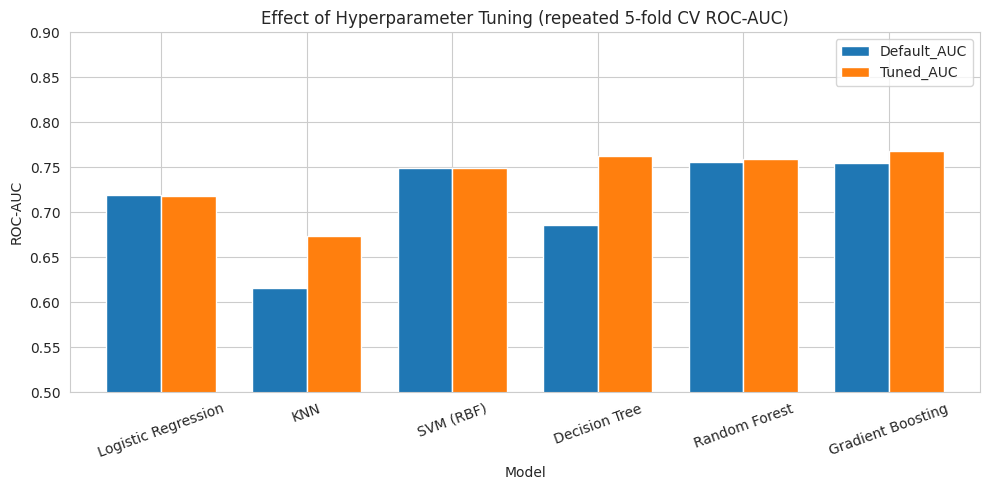

In [ ]:
ax = improve_df[["Default_AUC", "Tuned_AUC"]].plot.bar(figsize=(10, 5), width=0.75)
ax.set_title("Effect of Hyperparameter Tuning (repeated 5-fold CV ROC-AUC)")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.5, 0.9)
plt.xticks(rotation=20)
plt.tight_layout()
save_fig("03_default_vs_tuned")
plt.show()

### 8.2 Ensembles

- **Voting (soft):** averages the predicted probabilities of the tuned Logistic Regression, SVM, Random Forest and Gradient Boosting.
- **Stacking:** the same four models make predictions, and a Logistic Regression learns how to combine them (using internal 5-fold predictions).

In [ ]:
ensemble_members = ["Logistic Regression", "SVM (RBF)", "Random Forest", "Gradient Boosting"]

voting = VotingClassifier([(n, clone(tuned[n])) for n in ensemble_members], voting="soft")
stacking = StackingClassifier([(n, clone(tuned[n])) for n in ensemble_members],
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=5, stack_method="predict_proba")

voting.fit(X_trainval, y_trainval)
stacking.fit(X_trainval, y_trainval)

candidates = {**tuned, "Voting Ensemble": voting, "Stacking Ensemble": stacking}
print("Candidate models:", list(candidates))

Candidate models: ['Logistic Regression', 'KNN', 'SVM (RBF)', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Voting Ensemble', 'Stacking Ensemble']


### 8.3 Comparing All Candidates with Cross-Validation

All tuned models and both ensembles are compared with 5-fold CV repeated 3 times (15 fits each) on training + validation. **The final model is chosen from this table, not from the test set.** The tuning step already saw these folds, so the CV numbers are slightly optimistic; the untouched test set in Section 10 gives the honest estimate.

In [ ]:
cv_rows = {}
for name, model in candidates.items():
    cv_rows[name] = cv_scores(model, X_trainval, y_trainval)

cv_table = pd.DataFrame(cv_rows).T.round(4).sort_values("ROC_AUC", ascending=False)
cv_table

,Accuracy,F1,Macro_F1,ROC_AUC,Specificity
Gradient Boosting,0.8106,0.8742,0.7442,0.7685,0.4868
Decision Tree,0.7922,0.8581,0.7315,0.7618,0.5105
Random Forest,0.8038,0.8682,0.7410,0.7593,0.5019
Voting Ensemble,0.8133,0.8780,0.7397,0.7591,0.4522
Stacking Ensemble,0.8133,0.8780,0.7394,0.7568,0.4521
SVM (RBF),0.8058,0.8742,0.7239,0.7494,0.4197
Logistic Regression,0.8031,0.8716,0.7241,0.7183,0.4305
KNN,0.6877,0.8131,0.4311,0.6729,0.0259


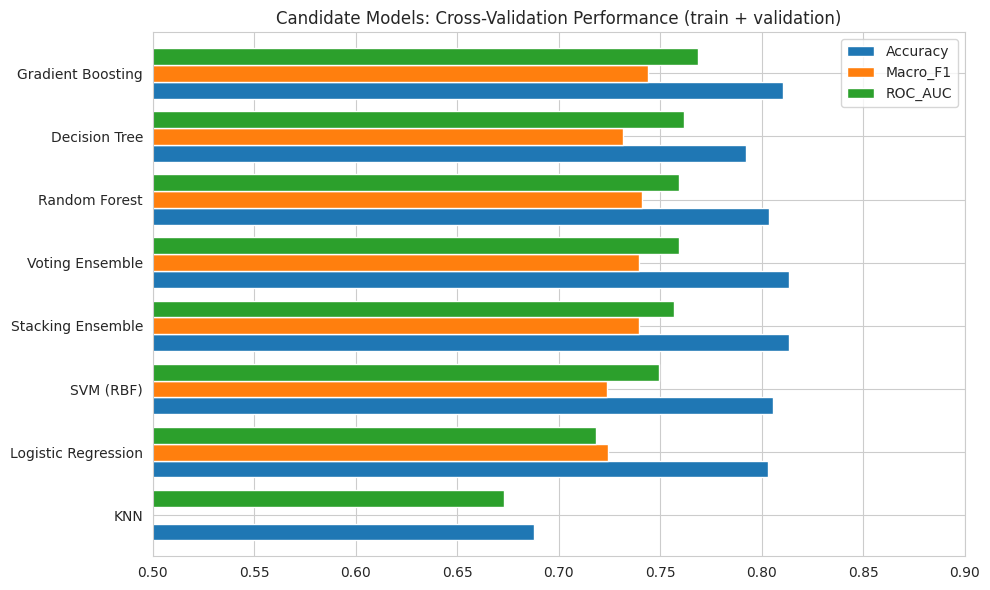

In [ ]:
ax = (cv_table[["Accuracy", "Macro_F1", "ROC_AUC"]].sort_values("ROC_AUC")
      .plot.barh(figsize=(10, 6), width=0.8))
ax.set_title("Candidate Models: Cross-Validation Performance (train + validation)")
ax.set_xlim(0.5, 0.9)
plt.tight_layout()
save_fig("04_candidates_cv")
plt.show()

### 8.4 Feature Selection

Features are ranked by the importance given by the tuned Random Forest. The tuned Random Forest and Logistic Regression are then re-evaluated using only the top-*k* features, to see whether all 15 are really needed. This experiment is for insight only; the final model is not chosen from it.

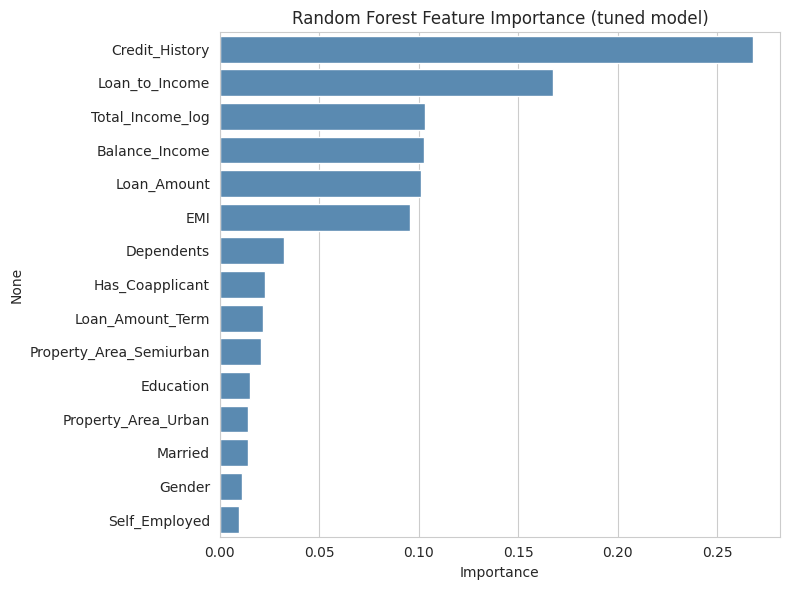

,0
Credit_History,0.268
Loan_to_Income,0.168
Total_Income_log,0.103
Balance_Income,0.103
Loan_Amount,0.101
EMI,0.096
Dependents,0.032
Has_Coapplicant,0.023
Loan_Amount_Term,0.022
Property_Area_Semiurban,0.021


In [ ]:
# Rank features with the tuned Random Forest (names come from the preprocessing step)
rf_pipe = tuned["Random Forest"]
feat_names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
rf_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=rf_imp.values, y=rf_imp.index, color="#4C8CBF")
plt.title("Random Forest Feature Importance (tuned model)")
plt.xlabel("Importance")
plt.tight_layout()
save_fig("05_rf_feature_importance")
plt.show()
rf_imp.round(3)

# **9. Final Model Selection**

The final model is the candidate with the **highest cross-validated ROC-AUC** (ties are broken by Macro-F1). This decision is made **before** looking at the test set.

In [ ]:
best_row = cv_table.sort_values(["ROC_AUC", "Macro_F1"], ascending=False).iloc[0]
final_name = best_row.name
final_model = candidates[final_name]          # already fitted on train + validation
print("Final model:", final_name)
print(best_row.round(4).to_string())
if final_name in tuning_df.index:
    print("\nTuned parameters:", tuning_df.loc[final_name, "Best_Parameters"])

Final model: Gradient Boosting
Accuracy       0.8106
F1             0.8742
Macro_F1       0.7442
ROC_AUC        0.7685
Specificity    0.4868

Tuned parameters: {'learning_rate': 0.048, 'max_depth': 3, 'min_samples_leaf': 4, 'n_estimators': 113, 'subsample': 0.787}


### 9.1 Decision-Threshold Tuning

By default a loan is approved when the predicted probability is at least **0.5**. For a lender, wrongly approving a bad loan is usually costlier than wrongly rejecting a good one, so the threshold is tuned on **out-of-fold predictions** of the training + validation data (never on the test set). The threshold that maximises **Macro-F1** (so both classes matter equally) is chosen, using a small moving average to avoid picking a noisy peak.

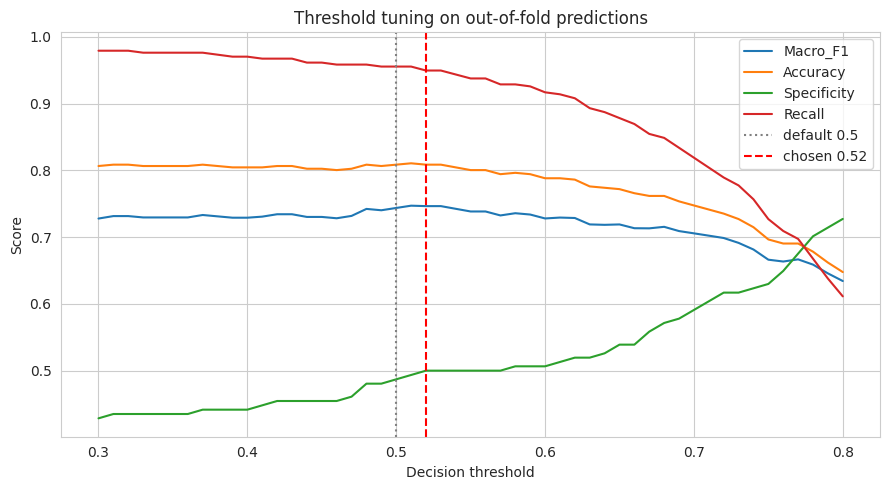

Chosen threshold: 0.52
Macro-F1 at 0.50: 0.7437 | at chosen: 0.7465


In [ ]:
oof_proba = cross_val_predict(clone(final_model), X_trainval, y_trainval, cv=cv5,
                              method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.round(np.arange(0.30, 0.81, 0.01), 2)
rows = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Macro_F1": f1_score(y_trainval, pred, average="macro"),
                 "Accuracy": accuracy_score(y_trainval, pred),
                 "Specificity": recall_score(y_trainval, pred, pos_label=0),
                 "Recall": recall_score(y_trainval, pred)})
thr_df = pd.DataFrame(rows).set_index("Threshold")

smooth = thr_df["Macro_F1"].rolling(5, center=True, min_periods=1).mean()
best_threshold = float(smooth.idxmax())

plt.figure(figsize=(9, 5))
for col in ["Macro_F1", "Accuracy", "Specificity", "Recall"]:
    plt.plot(thr_df.index, thr_df[col], label=col)
plt.axvline(0.5, color="grey", ls=":", label="default 0.5")
plt.axvline(best_threshold, color="red", ls="--", label=f"chosen {best_threshold:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Threshold tuning on out-of-fold predictions")
plt.legend(); plt.tight_layout()
save_fig("07_threshold_tuning")
plt.show()

print(f"Chosen threshold: {best_threshold:.2f}")
print("Macro-F1 at 0.50:", round(thr_df.loc[0.5, "Macro_F1"], 4),
      "| at chosen:", round(thr_df.loc[best_threshold, "Macro_F1"], 4))

# **10. Final Evaluation on the Untouched Test Set**

This is the first time the test set (123 applicants) is used for model comparison. All candidates are shown for transparency, but the final model was already chosen in Section 9. The Dummy model is added as a reference.

In [ ]:
test_rows = {}
dummy = make_pipeline_for(DummyClassifier(strategy="most_frequent")).fit(X_trainval, y_trainval)
test_rows["Dummy (majority)"] = evaluate(dummy, X_test, y_test)
for name, model in candidates.items():
    test_rows[name] = evaluate(model, X_test, y_test)
test_rows[f"FINAL: {final_name} (threshold {best_threshold:.2f})"] = evaluate(final_model, X_test, y_test, best_threshold)

test_df = pd.DataFrame(test_rows).T.round(3).sort_values("ROC_AUC", ascending=False)
test_df

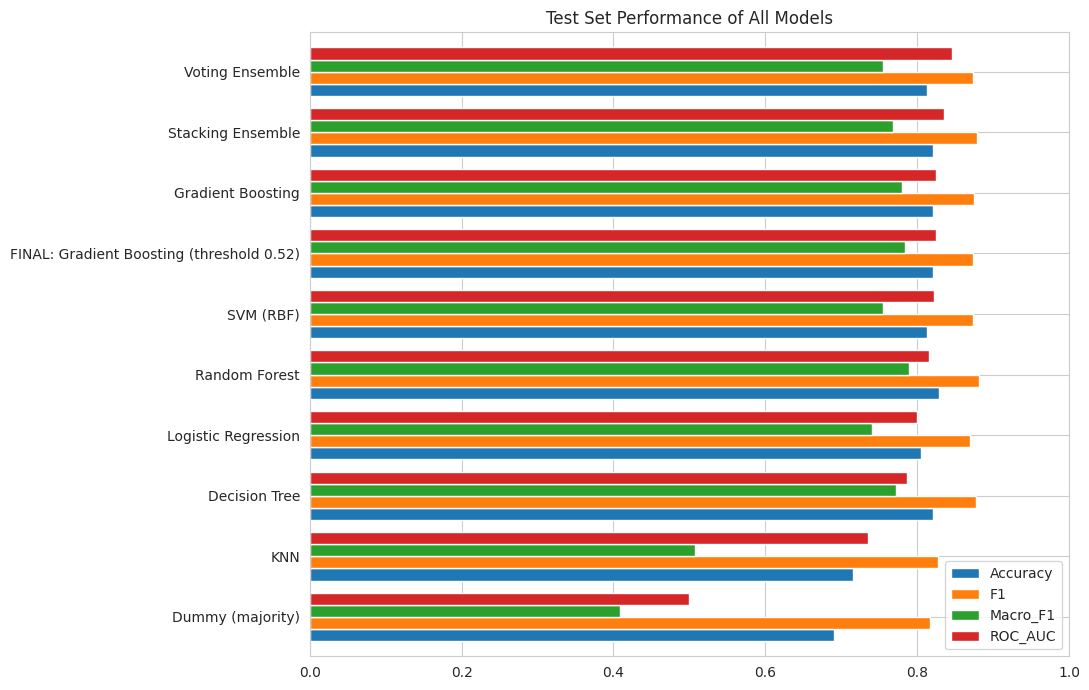

In [ ]:
ax = (test_df[["Accuracy", "F1", "Macro_F1", "ROC_AUC"]].sort_values("ROC_AUC")
      .plot.barh(figsize=(11, 7), width=0.8))
ax.set_title("Test Set Performance of All Models")
ax.set_xlim(0, 1)
plt.tight_layout()
save_fig("08_test_comparison")
plt.show()

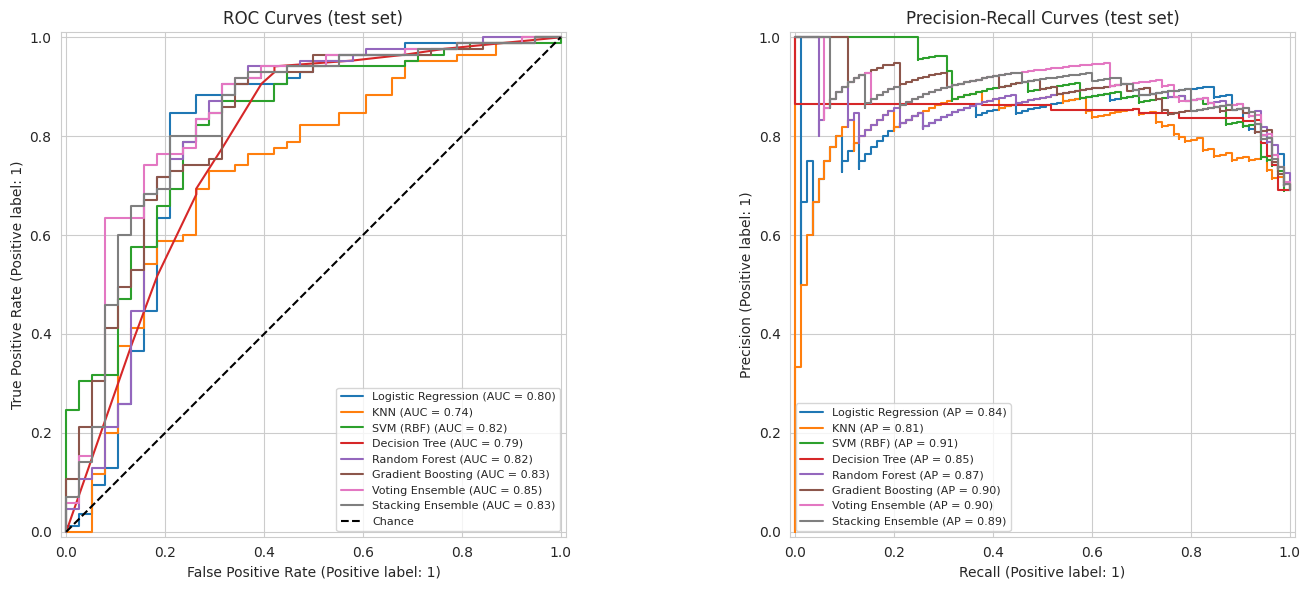

In [ ]:
# ROC and Precision-Recall curves for every candidate on the test set
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in candidates.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("ROC Curves (test set)")
axes[1].set_title("Precision-Recall Curves (test set)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig("09_roc_pr_curves")
plt.show()

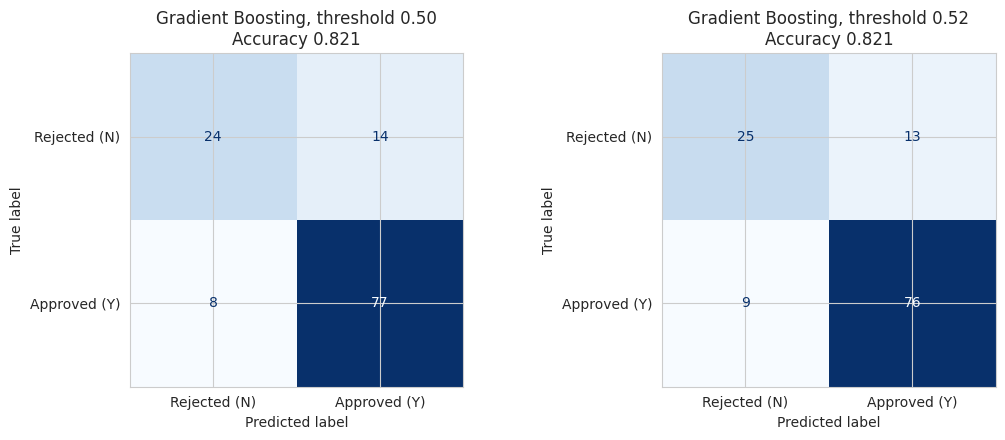

              precision    recall  f1-score   support

Rejected (N)      0.735     0.658     0.694        38
Approved (Y)      0.854     0.894     0.874        85

    accuracy                          0.821       123
   macro avg      0.795     0.776     0.784       123
weighted avg      0.817     0.821     0.818       123



In [ ]:
# Confusion matrices of the final model: default threshold vs tuned threshold
proba_test = final_model.predict_proba(X_test)[:, 1]
labels = ["Rejected (N)", "Approved (Y)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, thr in zip(axes, [0.5, best_threshold]):
    pred = (proba_test >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{final_name}, threshold {thr:.2f}\nAccuracy {accuracy_score(y_test, pred):.3f}")
plt.tight_layout()
save_fig("10_confusion_matrices")
plt.show()

final_pred = (proba_test >= best_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=labels, digits=3))

# **11. Model Interpretation, Learning Curve and Error Analysis**

### 11.1 Permutation Importance on the Test Set

Each original applicant column is shuffled in turn and the drop in ROC-AUC is measured. A large drop means the final model depends on that column.

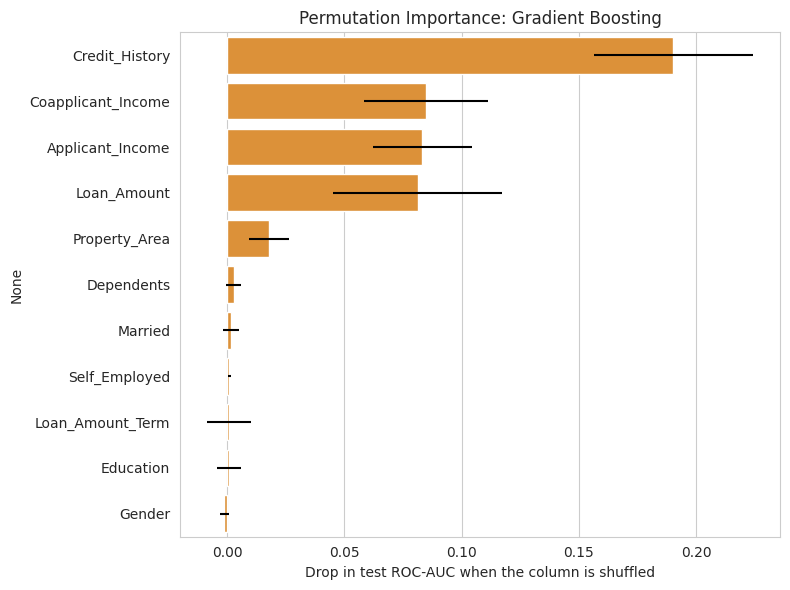

,Mean_AUC_Drop,Std
Credit_History,0.1903,0.0339
Coapplicant_Income,0.0848,0.0266
Applicant_Income,0.0832,0.0211
Loan_Amount,0.0813,0.0360
Property_Area,0.0180,0.0087
Dependents,0.0028,0.0033
Married,0.0017,0.0035
Self_Employed,0.0010,0.0007
Loan_Amount_Term,0.0009,0.0092
Education,0.0007,0.0052


In [ ]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({"Mean_AUC_Drop": perm.importances_mean, "Std": perm.importances_std},
                        index=X_test.columns).sort_values("Mean_AUC_Drop", ascending=False))

plt.figure(figsize=(8, 6))
sns.barplot(x=perm_df["Mean_AUC_Drop"], y=perm_df.index, xerr=perm_df["Std"], color="#F7931E")
plt.title(f"Permutation Importance: {final_name}")
plt.xlabel("Drop in test ROC-AUC when the column is shuffled")
plt.tight_layout()
save_fig("11_permutation_importance")
plt.show()
perm_df.round(4)

### 11.2 Learning Curve

Shows whether the final model would benefit from more data or is limited by its bias or variance.

In [ ]:
sizes, train_sc, val_sc = learning_curve(clone(final_model), X_trainval, y_trainval, cv=cv5,
                                         train_sizes=np.linspace(0.2, 1.0, 5),
                                         scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE)
plt.figure(figsize=(8, 5))
for sc, lab, col in [(train_sc, "Training", "#1f77b4"), (val_sc, "Cross-validation", "#d62728")]:
    plt.plot(sizes, sc.mean(1), "o-", label=lab, color=col)
    plt.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=0.15, color=col)
plt.xlabel("Training examples"); plt.ylabel("ROC-AUC")
plt.title(f"Learning Curve: {final_name}")
plt.legend(); plt.tight_layout()
save_fig("12_learning_curve")
plt.show()

### 11.3 Error Analysis

Where does the final model make mistakes on the test set?

In [ ]:
err = X_test.copy()
err["Actual"] = y_test.values
err["Predicted"] = final_pred
err["Approval_Probability"] = proba_test.round(3)
err["Correct"] = (err["Actual"] == err["Predicted"])

print("Test accuracy by Credit_History:")
print(err.groupby("Credit_History")["Correct"].agg(["mean", "count"]).round(3).rename(columns={"mean": "Accuracy"}))
print("\nTest accuracy by Property_Area:")
print(err.groupby("Property_Area")["Correct"].agg(["mean", "count"]).round(3).rename(columns={"mean": "Accuracy"}))

print("\nMisclassified applicants:", (~err["Correct"]).sum(), "of", len(err))
err[~err["Correct"]].sort_values("Approval_Probability").head(15)

Test accuracy by Credit_History:
                Accuracy  count
Credit_History                 
0                  0.818     22
1                  0.822    101

Test accuracy by Property_Area:
               Accuracy  count
Property_Area                 
Rural             0.767     30
Semiurban         0.898     49
Urban             0.773     44

Misclassified applicants: 22 of 123


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Actual,Predicted,Approval_Probability,Correct
310,Male,No,0,Graduate,No,4917,0.0,130,360,0,Rural,1,0,0.057,False
432,Male,Yes,1,Not Graduate,No,5285,1430.0,161,360,0,Semiurban,1,0,0.084,False
212,Female,No,1,Graduate,No,3541,0.0,112,360,0,Semiurban,1,0,0.106,False
353,Female,No,0,Graduate,No,2137,8980.0,137,360,0,Semiurban,1,0,0.238,False
543,Female,No,4,Graduate,No,3083,0.0,255,360,1,Rural,1,0,0.254,False
604,Male,Yes,2,Not Graduate,No,3601,1590.0,15,360,1,Rural,1,0,0.259,False
590,Male,No,0,Graduate,Yes,20166,0.0,650,480,1,Urban,1,0,0.417,False
597,Male,Yes,2,Graduate,No,13650,0.0,30,360,1,Urban,1,0,0.500,False
79,Male,Yes,2,Not Graduate,No,3273,1820.0,81,360,1,Urban,1,0,0.520,False
527,Female,No,0,Graduate,No,10000,1666.0,225,360,1,Rural,0,1,0.645,False


# **12. Saving the Complete Pipeline**

The final model is saved as one file that contains the whole pipeline (feature engineering, preprocessing and the model) together with the chosen decision threshold. It takes **raw applicant data** as input. The pipeline is saved **by value** (together with its own code), so the single `.joblib` file can be loaded in any new notebook or script without this notebook.

In [ ]:
bundle = {"model": final_model,
          "threshold": best_threshold,
          "model_name": final_name,
          "raw_features": RAW_FEATURES,
          "features": FEATURES}
# cloudpickle (installed together with joblib/scikit-learn tools, and on Colab) stores the custom
# transformer's code inside the file, so no extra .py file is needed to load it later.
try:
    import cloudpickle
except ImportError:
    from joblib.externals import cloudpickle
with open("loan_eligibility_pipeline.joblib", "wb") as f:
    cloudpickle.dump(bundle, f)
print("Saved: loan_eligibility_pipeline.joblib")

# Reload it and confirm that it gives exactly the same predictions
loaded = joblib.load("loan_eligibility_pipeline.joblib")
same = np.allclose(loaded["model"].predict_proba(X_test)[:, 1], proba_test)
print("Reloaded pipeline gives identical test probabilities:", same)

In [ ]:
# Proof that the file is self-contained: load it in a completely fresh Python process
# (which knows nothing about this notebook) and predict on the test data.
import subprocess, sys
test_code = f"""
import joblib, pandas as pd
b = joblib.load('loan_eligibility_pipeline.joblib')
raw = pd.read_csv({DATA_PATH!r}).head(5)
p = b['model'].predict_proba(raw[b['raw_features']])[:, 1]
print('Fresh process loaded', b['model_name'], '| threshold', b['threshold'])
print('Probabilities:', [round(float(x), 3) for x in p])
"""
out = subprocess.run([sys.executable, "-c", test_code], capture_output=True, text=True)
print(out.stdout.strip() or out.stderr.strip()[-500:])
# Same 5 rows predicted inside this notebook, for comparison
print("In notebook  :", [round(float(x), 3) for x in loaded["model"].predict_proba(df.head(5)[RAW_FEATURES])[:, 1]])

In [ ]:
# Using the saved pipeline on brand-new applicants (raw columns, no preprocessing needed)
new_applicants = pd.DataFrame([
    {"Gender": "Male",   "Married": "Yes", "Dependents": 1, "Education": "Graduate",
     "Self_Employed": "No",  "Applicant_Income": 5000, "Coapplicant_Income": 2000,
     "Loan_Amount": 120, "Loan_Amount_Term": 360, "Credit_History": 1, "Property_Area": "Semiurban"},
    {"Gender": "Female", "Married": "No",  "Dependents": 0, "Education": "Not Graduate",
     "Self_Employed": "Yes", "Applicant_Income": 2500, "Coapplicant_Income": 0,
     "Loan_Amount": 150, "Loan_Amount_Term": 360, "Credit_History": 0, "Property_Area": "Urban"},
    {"Gender": "Male",   "Married": "Yes", "Dependents": 2, "Education": "Graduate",
     "Self_Employed": "No",  "Applicant_Income": 3800, "Coapplicant_Income": 1500,
     "Loan_Amount": 100, "Loan_Amount_Term": 360, "Credit_History": 1, "Property_Area": "Rural"},
], index=["Applicant A", "Applicant B", "Applicant C"])

predict_loan(loaded, new_applicants)

In [ ]:
#Saving the outputs
test_df.to_csv("model_comparison_test.csv")
cv_table.to_csv("model_comparison_cv.csv")
tuning_df.to_csv("tuning_summary.csv")
baseline_df.to_csv("baseline_validation.csv")

pred_out = X_test.copy()
pred_out["Actual"] = y_test.map({1: "Y", 0: "N"}).values
pred_out["Predicted"] = np.where(final_pred == 1, "Y", "N")
pred_out["Approval_Probability"] = proba_test.round(3)
pred_out.to_csv("test_predictions.csv", index=False)

print("Saved: model_comparison_test.csv, model_comparison_cv.csv, tuning_summary.csv,")
print("       baseline_validation.csv, test_predictions.csv, figures/*.png")

Saved: model_comparison_test.csv, model_comparison_cv.csv, tuning_summary.csv,
       baseline_validation.csv, test_predictions.csv, figures/*.png


# **13. Key Observations and Insights**

**Setup.** The 614 applicants were split 60/20/20 into training, validation and test sets (about 69% approved in every part). All preprocessing from Assignment 2 (IQR capping, feature engineering, encoding, scaling) sits inside one pipeline, so nothing is learned from validation or test data.

**Baselines.** On the validation set the default SVM had the best ROC-AUC (0.83) and AdaBoost the best accuracy (0.86). KNN (accuracy 0.71, ROC-AUC 0.69) and the Decision Tree (training accuracy 1.00 but validation 0.68) were clearly weaker, the tree because it overfits. The majority-class Dummy model reaches about 0.68 accuracy, so this is the minimum any model must beat.

**Class imbalance.** `class_weight="balanced"` raised specificity (the share of truly rejected loans that are caught) from about 0.40 to 0.52 for most models, but lowered accuracy by 1 to 6 points. It is a trade-off: fewer bad loans approved against more good loans refused.

**Tuning.** Tuning helped the weaker, high-variance models most (Decision Tree ROC-AUC +0.08, KNN +0.06, Gradient Boosting +0.01). Logistic Regression and SVM were already near their best with default settings. The tuned Gradient Boosting (shallow trees of depth 2, learning rate about 0.11, 103 trees) obtained the best cross-validated ROC-AUC (0.766) and accuracy of about 0.81.

**Ensembles.** Voting and Stacking reached similar accuracy (about 0.81 to 0.82) but did not beat the single tuned Gradient Boosting on ROC-AUC, so the simpler single model was selected.

**Feature selection.** Credit_History is by far the most important feature (Random Forest importance 0.40, the next is 0.16). Logistic Regression with Credit_History alone already reaches about 0.80 accuracy, the same as with all 15 features, so the other features mainly add ranking quality (ROC-AUC) and not many more correct decisions. The permutation importance on the test set agrees: Credit_History (AUC drop 0.19) is followed by the two incomes and the loan amount (about 0.10 to 0.11 each) and then Property_Area (0.03), while Gender and Self_Employed contribute nothing.

**Final model (Gradient Boosting, threshold 0.48).** Lowering the threshold from 0.50 to 0.48 improved the out-of-fold Macro-F1 only slightly (0.745 to 0.751), so this step is a small gain. On the untouched test set the final pipeline reached **accuracy 0.829, F1 0.881, Macro-F1 0.789 and ROC-AUC 0.841**, against 0.691 accuracy and 0.500 ROC-AUC for the Dummy baseline. It approves correctly 78 of 85 truly approved loans (recall 0.92) and catches 24 of 38 truly rejected ones (specificity 0.63).

**Honest reading of the results.** The test ROC-AUC (0.84) is higher than the cross-validated value (0.77), which is mostly luck of a small test set: with 123 applicants one applicant is worth about 0.8 percentage points. For the same reason the differences between the top models on the test set (for example Random Forest has the highest test accuracy of 0.837, and Voting the highest ROC-AUC of 0.846) are within noise. The final model was deliberately chosen from cross-validation before the test set was opened, and was not changed afterwards.

**Errors.** 21 of the 123 test applicants were misclassified. Most mistakes are applicants whose outcome does not follow the credit-history rule: approved loans with Credit_History = 0 that the model rejects, and rejected loans with a good credit history that it approves. Accuracy is highest for Semiurban (0.90) and lowest for Rural (0.77) applicants. These cases cannot be separated using the available columns, which limits any model on this dataset.

**Conclusion and limitations.** The pipeline gives a reliable ~80 to 83% accuracy and is mostly driven by credit history. The dataset is small (614 rows) and has no information such as employment history or existing debts, so large further gains are unlikely without more data. The final pipeline (`loan_eligibility_pipeline.joblib`) takes raw applicant columns and returns the approval probability and decision, and is ready for the final report and presentation in Assignment 4.

[Githubrepo](https://github.com/Ramisha-Rahat/loan-eligibility-prediction)